<a href="https://colab.research.google.com/github/jullanarshamsi2008-spec/HAR-Walking-Recognition/blob/main/human_activity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
uploaded = files.upload()
print("Uploaded:", list(uploaded.keys()))

Saving Acceleration with g 2026-10-29 18-41-56.zip to Acceleration with g 2026-10-29 18-41-56.zip
Uploaded: ['Acceleration with g 2026-10-29 18-41-56.zip']


In [10]:
import zipfile
import os

zip_file = "Acceleration with g 2026-10-29 18-41-56.zip"

# Extract ZIP file
with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall("walking_data")

print("ZIP file extracted successfully!")

# Show extracted files
for root, folders, files_list in os.walk("walking_data"):
    for file in files_list:
        print(os.path.join(root, file))

ZIP file extracted successfully!
walking_data/Raw Data.csv
walking_data/meta/time.csv
walking_data/meta/device.csv


Saving Acceleration with g 2026-10-29 18-41-56.zip to Acceleration with g 2026-10-29 18-41-56 (1).zip
Rows and columns: (60026, 5)
Duration (s): 120.1
Samples per second: 500
   Time (s)  Acceleration x (m/s^2)  Acceleration y (m/s^2)  \
0  0.044662               -0.114922                9.402329   
1  0.046663               -0.090980                9.409512   
2  0.048663               -0.052672                9.399935   
3  0.050663               -0.083797                9.390358   
4  0.052663               -0.105345                9.426271   

   Acceleration z (m/s^2)  Absolute acceleration (m/s^2)  
0                2.537854                       9.739492  
1                2.585738                       9.758751  
2                2.679112                       9.774415  
3                2.573767                       9.737049  
4                2.499547                       9.752611  
Saved: sitting_dataset_full.csv | Rows: 60026


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

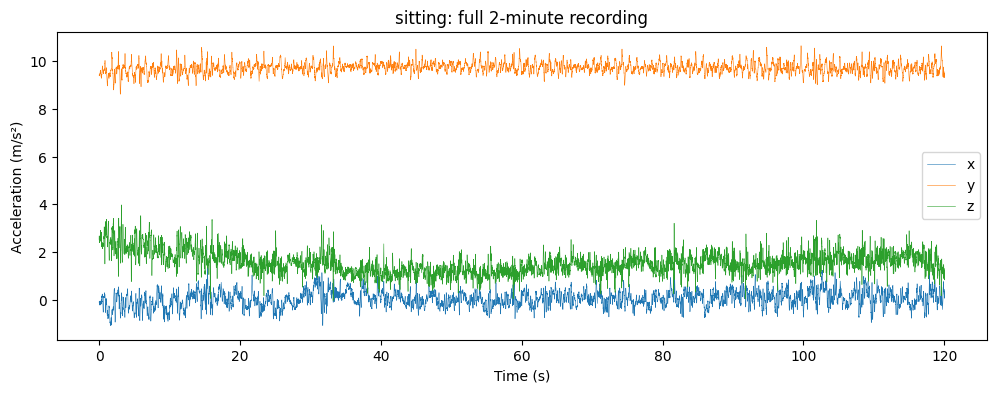

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import zipfile, glob, os
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

# ---- change this to your activity ----
LABEL = "sitting"
# --------------------------------------

# 1. Upload the new phyphox zip
uploaded = files.upload()
zip_name = list(uploaded.keys())[0]

# 2. Unzip and find Raw Data.csv (works with any capitalisation)
folder = "phyphox_data_2"
with zipfile.ZipFile(zip_name, "r") as z:
    z.extractall(folder)
csv_path = [p for p in glob.glob(folder + "/**/*.csv", recursive=True)
            if os.path.basename(p).lower() == "raw data.csv"][0]
df = pd.read_csv(csv_path)

# 3. Check the data
duration = df["Time (s)"].iloc[-1] - df["Time (s)"].iloc[0]
print("Rows and columns:", df.shape)
print("Duration (s):", round(duration, 1))
print("Samples per second:", round(len(df) / duration))
print(df.head())

# 4. Reset time to 0 and add the label
full = df.copy()
full["Time (s)"] = full["Time (s)"] - full["Time (s)"].iloc[0]
full["label"] = LABEL

# 5. Save the dataset and download it
out_name = f"{LABEL}_dataset_full.csv"
full.to_csv(out_name, index=False)
print("Saved:", out_name, "| Rows:", len(full))
files.download(out_name)

# 6. Plot the full 2 minutes
plt.figure(figsize=(12, 4))
plt.plot(full["Time (s)"], full["Acceleration x (m/s^2)"], label="x", linewidth=0.4)
plt.plot(full["Time (s)"], full["Acceleration y (m/s^2)"], label="y", linewidth=0.4)
plt.plot(full["Time (s)"], full["Acceleration z (m/s^2)"], label="z", linewidth=0.4)
plt.xlabel("Time (s)")
plt.ylabel("Acceleration (m/s²)")
plt.title(f"{LABEL}: full 2-minute recording")
plt.legend()
plt.savefig(f"{LABEL}_full.png", dpi=200, bbox_inches="tight")
plt.show()
files.download(f"{LABEL}_full.png")

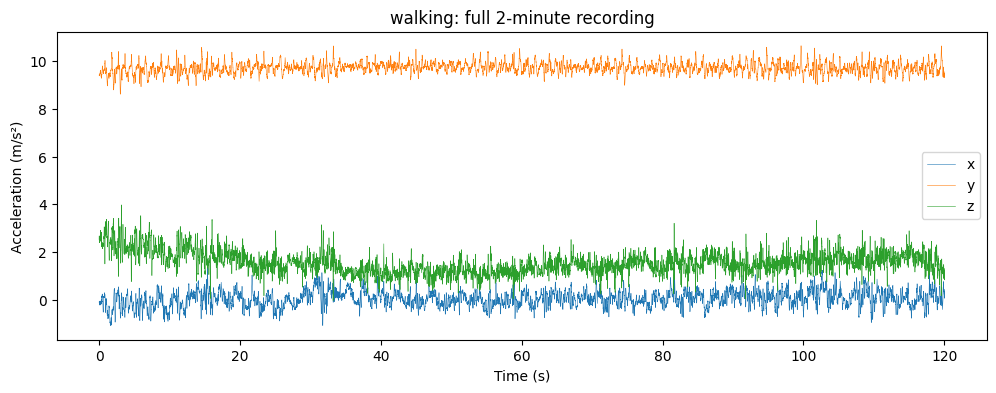

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
LABEL = "walking"   # <- change to your real activity

full["label"] = LABEL
out_name = f"{LABEL}_dataset_full.csv"
full.to_csv(out_name, index=False)

import matplotlib.pyplot as plt
from google.colab import files

plt.figure(figsize=(12, 4))
plt.plot(full["Time (s)"], full["Acceleration x (m/s^2)"], label="x", linewidth=0.4)
plt.plot(full["Time (s)"], full["Acceleration y (m/s^2)"], label="y", linewidth=0.4)
plt.plot(full["Time (s)"], full["Acceleration z (m/s^2)"], label="z", linewidth=0.4)
plt.xlabel("Time (s)")
plt.ylabel("Acceleration (m/s²)")
plt.title(f"{LABEL}: full 2-minute recording")
plt.legend()
plt.savefig(f"{LABEL}_full.png", dpi=200, bbox_inches="tight")
plt.show()

files.download(out_name)
files.download(f"{LABEL}_full.png")

In [5]:
import pandas as pd
from google.colab import files
import io

# Upload raw walking sensor data
uploaded = files.upload()

# Read the CSV file
file_name = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[file_name]))

# Display the dataset
print("PRIVATE WALKING DATASET")
print("First 5 rows:")
display(df.head())

# Show columns and data types
print("Dataset information:")
df.info()

# Check dataset size
print("Dataset shape:", df.shape)

Saving Raw Data.csv to Raw Data.csv
PRIVATE WALKING DATASET
First 5 rows:


,Time (s),Acceleration x (m/s^2),Acceleration y (m/s^2),Acceleration z (m/s^2),Absolute acceleration (m/s^2)
0,0.044662,-0.114922,9.402329,2.537854,9.739492
1,0.046663,-0.090980,9.409512,2.585738,9.758751
2,0.048663,-0.052672,9.399935,2.679112,9.774415
3,0.050663,-0.083797,9.390358,2.573767,9.737049
4,0.052663,-0.105345,9.426271,2.499547,9.752611


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60026 entries, 0 to 60025
Data columns (total 5 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Time (s)                       60026 non-null  float64
 1   Acceleration x (m/s^2)         60026 non-null  float64
 2   Acceleration y (m/s^2)         60026 non-null  float64
 3   Acceleration z (m/s^2)         60026 non-null  float64
 4   Absolute acceleration (m/s^2)  60026 non-null  float64
dtypes: float64(5)
memory usage: 2.3 MB
Dataset shape: (60026, 5)


In [6]:
# STEP 4: DATA QUALITY CHECK AND CLEANING

# Make a copy of the original dataset
clean_df = df.copy()

# Check missing values
print("Missing values:")
print(clean_df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:")
print(clean_df.duplicated().sum())

# Remove duplicate rows
clean_df = clean_df.drop_duplicates()

# Sort data by time
clean_df = clean_df.sort_values("Time (s)")

# Check time range
print("\nRecording starts at:", clean_df["Time (s)"].min(), "seconds")
print("Recording ends at:", clean_df["Time (s)"].max(), "seconds")

# Check acceleration statistics
print("\nAcceleration summary:")
display(clean_df.describe())

print("\nCleaned dataset shape:", clean_df.shape)

Missing values:
Time (s)                         0
Acceleration x (m/s^2)           0
Acceleration y (m/s^2)           0
Acceleration z (m/s^2)           0
Absolute acceleration (m/s^2)    0
dtype: int64

Duplicate rows:
0

Recording starts at: 0.044661703 seconds
Recording ends at: 120.1004233 seconds

Acceleration summary:


,Time (s),Acceleration x (m/s^2),Acceleration y (m/s^2),Acceleration z (m/s^2),Absolute acceleration (m/s^2)
count,60026.000000,60026.000000,60026.000000,60026.000000,60026.000000
mean,60.075419,0.056550,9.713399,1.562333,9.854872
std,34.656368,0.333767,0.234134,0.460350,0.232012
min,0.044662,-1.079785,8.609849,-0.028730,8.806526
25%,30.062955,-0.155623,9.572318,1.244985,9.709112
50%,60.075459,0.057461,9.713575,1.515530,9.844720
75%,90.087971,0.275333,9.847651,1.821988,9.989097
max,120.100423,1.687912,10.637737,3.976769,10.925592



Cleaned dataset shape: (60026, 5)


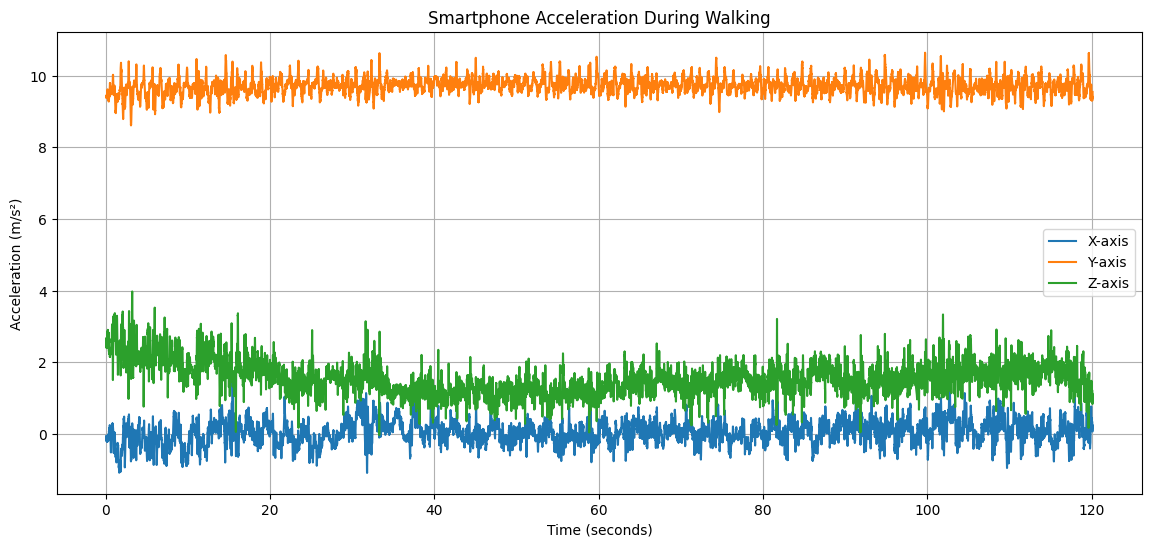

In [7]:
import matplotlib.pyplot as plt

# Plot acceleration on all three axes
plt.figure(figsize=(14, 6))

plt.plot(clean_df["Time (s)"],
         clean_df["Acceleration x (m/s^2)"],
         label="X-axis")

plt.plot(clean_df["Time (s)"],
         clean_df["Acceleration y (m/s^2)"],
         label="Y-axis")

plt.plot(clean_df["Time (s)"],
         clean_df["Acceleration z (m/s^2)"],
         label="Z-axis")

plt.title("Smartphone Acceleration During Walking")
plt.xlabel("Time (seconds)")
plt.ylabel("Acceleration (m/s²)")
plt.legend()
plt.grid(True)
plt.show()